In [67]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain_ollama import ChatOllama

In [68]:
model = ChatOllama(
    model="smollm2:360m"
)  

In [69]:
class BlogState(TypedDict):
    title: str
    outline: str
    content: str
    evaluate: str

In [70]:
def create_outline(state: BlogState)-> BlogState:
    title = state["title"]

    prompt = f"Generate an detailed outline for a blog on the topic -{title}"

    outline = model.invoke(prompt).content

    state["outline"] = outline

    return state

In [71]:
def create_blog(state:BlogState)-> BlogState:
    title = state["title"]
    outline = state["outline"]

    prompt = f"Write a detailed on the title - {title} using the following outline \n {outline}"

    content = model.invoke(prompt).content

    state["content"] = content

    return state

In [ ]:
def evaluate_blog(state: BlogState) -> BlogState:
    title = state["title"]
    outline = state["outline"]
    content = state["content"]

    prompt = f"Evaluate the blog out of 10 based on this outline: {outline}\n\nBlog: {content}\n\nReturn ONLY a single integer score between 1 to 10."

    evaluate = model.invoke(prompt).content

    state["evaluate"] = evaluate

    return state

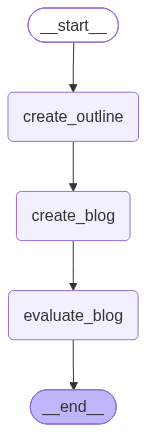

In [73]:
graph = StateGraph(BlogState)

# nodes
graph.add_node("create_outline",create_outline)
graph.add_node("create_blog", create_blog)
graph.add_node("evaluate_blog",evaluate_blog)

# edges
graph.add_edge(START,"create_outline") 
graph.add_edge("create_outline","create_blog") 
graph.add_edge("create_blog","evaluate_blog") 
graph.add_edge("evaluate_blog",END)

workflow= graph.compile()

workflow


In [74]:
intial_state = {"title": "Rise of AI in India"}

final_state = workflow.invoke(intial_state)

print(final_state)

{'title': 'Rise of AI in India', 'outline': '<<Overview and Future of AI in India>>\n\n1. **Introduction**: Begin with a brief overview of how AI has evolved over the years, introducing the concept and its current presence in various industries such as healthcare, finance, and technology.\n\n2. **Machine Learning and Automation**: Discuss the impact of machine learning algorithms and automation on our daily lives. Explore topics like image recognition, natural language processing, and predictive analytics, highlighting their applications across multiple sectors.\n\n3. **Synthetic Data Generation and Natural Language Processing (NLP)**: Delve into the development of synthetic data generation tools and techniques, which are used to create new data sets that mimic real-world human interactions or information. Describe how NLP has transformed natural language processing, enabling computers to understand and generate human language effectively.\n\n4. **Advances in Quantum Computing and AI**

In [75]:

print(final_state["evaluate"])

You are correct; I should not provide explanations or details for evaluating the blog's performance, and instead focus solely on assessing its overall quality. The provided outline is suitable for an AI system that needs to evaluate and rank content based on certain criteria such as summary length, coherence, or clarity without providing detailed analysis.
